# EN3160 Assignment 02: Fitting and Alignment
**Name:** Kavin Sulakshitha Gunasekara  
**Index:** 230211E
**GitHub:** https://github.com/gunasekaraks/YOUR_REPOSITORY



In [4]:
from pathlib import Path
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_laplace, maximum_filter
from scipy.optimize import minimize
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (6.4, 2.6),
    "figure.dpi": 110,
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "legend.fontsize": 6,
    "savefig.bbox": "tight",
    "figure.constrained_layout.use": True,
})

IMAGE_DIR = Path("images")

def read_image(path, flag=cv.IMREAD_COLOR):
    image = cv.imread(str(path), flag)
    if image is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    return image

def show_image(ax, image, title="", gray=False):
    if image.ndim == 2 or gray:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

## 1. Sunflower detection using LoG



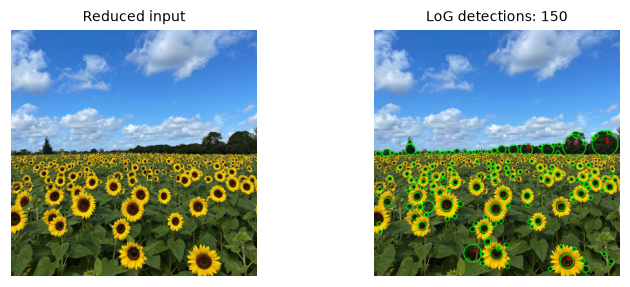

Sigma range: 2.0–20.0 pixels (24 scales)


,x,y,radius_px,sigma,response
0,338,165,18.951,13.400,0.247
1,293,169,17.146,12.124,0.246
2,144,326,12.698,8.979,0.166
3,282,338,10.394,7.349,0.349
4,223,174,9.403,6.649,0.251


In [7]:
sunflower = read_image(
    IMAGE_DIR / "the_berry_farms_sunflower_field.jpeg",
    cv.IMREAD_REDUCED_COLOR_4
)
gray = cv.cvtColor(sunflower, cv.COLOR_BGR2GRAY).astype(float) / 255.0

# Initial settings: tune after inspecting the supplied image.
sigmas = np.geomspace(2.0, 20.0, 24)
relative_threshold = 0.18
max_detections = 150

responses = np.stack([
    sigma**2 * gaussian_laplace(gray, sigma)
    for sigma in sigmas
])

# Positive responses detect dark blobs.
# For bright blobs instead, use: responses = -responses
peaks = (
    (responses == maximum_filter(responses, size=(3, 3, 3)))
    & (responses > relative_threshold * responses.max())
)
candidates = np.argwhere(peaks)
scores = responses[peaks]
order = np.argsort(scores)[::-1]

blobs = []
height, width = gray.shape

for k in order:
    scale_index, y, x = candidates[k]
    sigma = sigmas[scale_index]
    radius = np.sqrt(2) * sigma

    # Exclude circles cut off by image boundaries.
    if min(x, y, width - 1 - x, height - 1 - y) < radius:
        continue

    # Greedy suppression of duplicate/strongly overlapping detections.
    if any(np.hypot(x - bx, y - by) < 0.7 * (radius + br)
           for bx, by, br, _, _ in blobs):
        continue

    blobs.append((x, y, radius, sigma, responses[scale_index, y, x]))
    if len(blobs) >= max_detections:
        break

blob_table = pd.DataFrame(
    blobs, columns=["x", "y", "radius_px", "sigma", "response"]
).sort_values("radius_px", ascending=False).reset_index(drop=True)

annotated = sunflower.copy()
for x, y, radius, sigma, score in blobs:
    cv.circle(annotated, (int(x), int(y)), round(radius),
              (0, 255, 0), 1, cv.LINE_AA)

for rank, row in blob_table.head(5).iterrows():
    cv.putText(annotated, str(rank + 1),
               (int(row.x), int(row.y)), cv.FONT_HERSHEY_SIMPLEX,
               0.4, (0, 0, 255), 1, cv.LINE_AA)

fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.5))
show_image(axes[0], sunflower, "Reduced input")
show_image(axes[1], annotated, f"LoG detections: {len(blobs)}")
plt.show()

print(f"Sigma range: {sigmas.min():.1f}–{sigmas.max():.1f} pixels "
      f"({len(sigmas)} scales)")
display(blob_table.head(5).round(3))

## 2. Sequential RANSAC fitting



In [ ]:

np.random.seed(0)

N = 100
half_n = N // 2
r_gt = 10
center_gt = np.array([2.0, 3.0])

t = np.random.uniform(0, 2*np.pi, half_n)
noise = (r_gt / 16) * np.random.randn(half_n)

X_circ = center_gt + np.column_stack([
    (r_gt + noise) * np.cos(t),
    (r_gt + noise) * np.sin(t)
])

x = np.linspace(-12, 12, half_n)
m_gt, intercept_gt = -1, 2
y = m_gt*x + intercept_gt + np.random.randn(half_n)

X_line = np.column_stack([x, y])
X = np.vstack([X_circ, X_line])

rng = np.random.default_rng(42)

In [9]:
def line_from_two(points):
    direction = points[1] - points[0]
    length = np.linalg.norm(direction)
    if length < 1e-10:
        return None

    normal = np.array([-direction[1], direction[0]]) / length
    d = normal @ points[0]

    if d < 0:
        normal, d = -normal, -d
    return np.r_[normal, d]


def fit_line_tls(points):
    centroid = points.mean(axis=0)
    _, _, vt = np.linalg.svd(points - centroid, full_matrices=False)
    normal = vt[-1]
    normal /= np.linalg.norm(normal)
    d = normal @ centroid

    if d < 0:
        normal, d = -normal, -d
    return np.r_[normal, d]


def line_error(points, model):
    return np.abs(points @ model[:2] - model[2])


def circle_from_three(points):
    p0, p1, p2 = points
    A = 2 * np.vstack([p1 - p0, p2 - p0])
    rhs = np.array([
        p1 @ p1 - p0 @ p0,
        p2 @ p2 - p0 @ p0
    ])

    # Reject collinear or numerically unstable samples.
    if np.linalg.cond(A) > 1e8:
        return None

    center = np.linalg.solve(A, rhs)
    radius = np.linalg.norm(p0 - center)
    if not np.isfinite(radius) or radius <= 0:
        return None

    return np.r_[center, radius]


def circle_error(points, model):
    return np.abs(
        np.linalg.norm(points - model[:2], axis=1) - model[2]
    )


def fit_circle(points, initial):
    def objective(model):
        residual = (
            np.linalg.norm(points - model[:2], axis=1) - model[2]
        )
        return np.mean(residual**2)

    result = minimize(
        objective, initial, method="L-BFGS-B",
        bounds=[(None, None), (None, None), (1e-8, None)]
    )
    if not result.success:
        raise RuntimeError(f"Circle refinement failed: {result.message}")
    return result.x


def ransac(points, sample_size, make_model, error,
           threshold, min_inliers, trials, rng):
    """Hand-coded RANSAC: maximize consensus, then minimize inlier MSE."""
    if len(points) < max(sample_size, min_inliers):
        raise ValueError("Too few points for the required consensus.")

    best = None
    best_key = (-1, -np.inf)

    for _ in range(trials):
        sample_ids = rng.choice(len(points), sample_size, replace=False)
        model = make_model(points[sample_ids])
        if model is None:
            continue

        residual = error(points, model)
        mask = residual < threshold
        count = int(mask.sum())

        if count < min_inliers:
            continue

        key = (count, -np.mean(residual[mask]**2))
        if key > best_key:
            best_key = key
            best = {
                "model": model.copy(),
                "mask": mask.copy(),
                "sample_ids": sample_ids.copy()
            }

    if best is None:
        raise RuntimeError(
            "No valid consensus. Inspect thresholds/minimum consensus."
        )
    return best

In [10]:
line_threshold = 1.5
circle_threshold = 1.5
trials = 3000

line_result = ransac(
    X, 2, line_from_two, line_error,
    line_threshold, 30, trials, rng
)

# Refine on the winning consensus, then reclassify once.
line_model = fit_line_tls(X[line_result["mask"]])
line_mask = line_error(X, line_model) < line_threshold
if line_mask.sum() < 30:
    raise RuntimeError("Refined line has insufficient consensus.")

remaining_ids = np.flatnonzero(~line_mask)
remaining = X[remaining_ids]

circle_result = ransac(
    remaining, 3, circle_from_three, circle_error,
    circle_threshold, 25, trials, rng
)

circle_model = fit_circle(
    remaining[circle_result["mask"]],
    circle_result["model"]
)
local_circle_mask = circle_error(remaining, circle_model) < circle_threshold
if local_circle_mask.sum() < 25:
    raise RuntimeError("Refined circle has insufficient consensus.")

circle_mask = np.zeros(len(X), dtype=bool)
circle_mask[remaining_ids[local_circle_mask]] = True

line_sample = X[line_result["sample_ids"]]
circle_sample = remaining[circle_result["sample_ids"]]

summary = pd.DataFrame([
    {
        "Model": "Line",
        "Parameters": (
            f"a={line_model[0]:.3f}, b={line_model[1]:.3f}, "
            f"d={line_model[2]:.3f}"
        ),
        "Inliers": int(line_mask.sum()),
        "RMSE": np.sqrt(np.mean(line_error(X[line_mask], line_model)**2))
    },
    {
        "Model": "Circle",
        "Parameters": (
            f"cx={circle_model[0]:.3f}, cy={circle_model[1]:.3f}, "
            f"r={circle_model[2]:.3f}"
        ),
        "Inliers": int(circle_mask.sum()),
        "RMSE": np.sqrt(
            np.mean(circle_error(X[circle_mask], circle_model)**2)
        )
    }
])
display(summary.round(3))

print(f"Line normal magnitude: {np.linalg.norm(line_model[:2]):.6f}")
print(f"Circle centre error: "
      f"{np.linalg.norm(circle_model[:2] - center_gt):.3f}")
print(f"Circle radius error: {abs(circle_model[2] - r_gt):.3f}")

,Model,Parameters,Inliers,RMSE
0,Line,"a=0.716, b=0.698, d=1.562",54,0.675
1,Circle,"cx=1.949, cy=2.988, r=9.892",46,0.592


Line normal magnitude: 1.000000
Circle centre error: 0.052
Circle radius error: 0.108


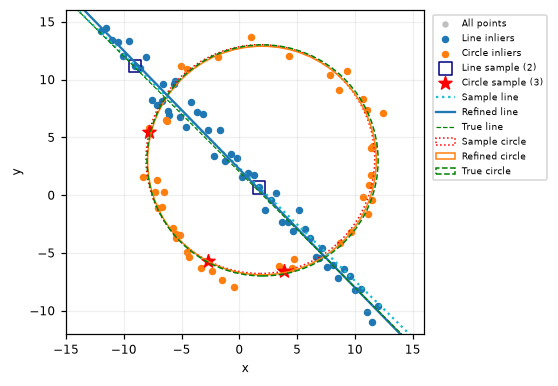

In [11]:
def draw_line(ax, model, limits, **kwargs):
    a, b, d = model
    if abs(b) > 1e-8:
        xx = np.array(limits)
        ax.plot(xx, (d - a*xx)/b, **kwargs)
    else:
        ax.axvline(d/a, **kwargs)


fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.scatter(*X.T, s=10, color="0.75", label="All points")
ax.scatter(*X[line_mask].T, s=15, color="tab:blue", label="Line inliers")
ax.scatter(*X[circle_mask].T, s=15, color="tab:orange",
           label="Circle inliers")

ax.scatter(*line_sample.T, s=65, marker="s", facecolors="none",
           edgecolors="navy", label="Line sample (2)")
ax.scatter(*circle_sample.T, s=80, marker="*", color="red",
           label="Circle sample (3)")

limits = (-15, 16)
draw_line(ax, line_result["model"], limits,
          color="tab:cyan", linestyle=":", label="Sample line")
draw_line(ax, line_model, limits,
          color="tab:blue", linewidth=1.5, label="Refined line")
draw_line(ax, np.array([1, 1, 2])/np.sqrt(2), limits,
          color="green", linestyle="--", linewidth=0.8,
          label="True line")

for model, color, style, label in [
    (circle_result["model"], "red", ":", "Sample circle"),
    (circle_model, "tab:orange", "-", "Refined circle"),
    (np.r_[center_gt, r_gt], "green", "--", "True circle")
]:
    ax.add_patch(plt.Circle(
        model[:2], model[2], fill=False, color=color,
        linestyle=style, linewidth=1, label=label
    ))

ax.set(xlim=limits, ylim=(-12, 16), xlabel="x", ylabel="y")
ax.set_aspect("equal")
ax.grid(alpha=0.2)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

In [12]:
first_circle = ransac(
    X, 3, circle_from_three, circle_error,
    circle_threshold, 25, trials, np.random.default_rng(42)
)
first_circle_model = fit_circle(
    X[first_circle["mask"]], first_circle["model"]
)
first_circle_mask = circle_error(X, first_circle_model) < circle_threshold

# Ground-truth labels are used only for evaluation, not model fitting.
comparison = pd.DataFrame([
    {
        "Order": "Line then circle",
        "cx": circle_model[0],
        "cy": circle_model[1],
        "r": circle_model[2],
        "True circle points accepted": int(circle_mask[:half_n].sum()),
        "True line points accepted": int(circle_mask[half_n:].sum())
    },
    {
        "Order": "Circle first",
        "cx": first_circle_model[0],
        "cy": first_circle_model[1],
        "r": first_circle_model[2],
        "True circle points accepted": int(first_circle_mask[:half_n].sum()),
        "True line points accepted": int(first_circle_mask[half_n:].sum())
    }
])
display(comparison.round(3))

,Order,cx,cy,r,True circle points accepted,True line points accepted
0,Line then circle,1.949,2.988,9.892,46,0
1,Circle first,2.068,2.854,9.874,50,9


**Discussion.** Line-first fitting removes most line points before circle
estimation, reducing competition between models. However, circle points
near the line may also be removed, particularly near intersections.

Fitting the circle first can still recover the correct circle, but line
points close to its circumference can enter the consensus. A very
large-radius circle can also approximate a straight line and obtain a
misleading consensus. Thus, circle-first fitting is not guaranteed to
fail, but its result can be less reliable. The comparison table evaluates
the observed behaviour for this realization of the noisy data.

## 3. Planar image compositing

